In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

notebook_file = globals().get("__vsc_ipynb_file__")
NOTEBOOK_DIR = Path(notebook_file).resolve().parent if notebook_file else Path.cwd()
sys.path.insert(0, str(NOTEBOOK_DIR))



DATE = "AsOfDate"



prices = pl.read_csv(NOTEBOOK_DIR /".."/ "prices/example_prices.csv", try_parse_dates=True).rename({"dates": DATE})
instruments = [c for c in prices.columns if c != DATE]
ret = prices.select(DATE, pl.col(instruments).diff())

diamonds
[[-0.01521616  0.00591071 -0.02528797  0.00311017]
 [-0.01324832 -0.0040853   0.00394817  0.00570748]
 [ 0.01076409  0.01505414 -0.00048296  0.00589118]
 [ 0.01974786 -0.00129818  0.01217378  0.02175389]
 [-0.01368071  0.00779909  0.02914211  0.00370131]
 [-0.01317477 -0.00359142 -0.00812063  0.00157028]
 [ 0.00312278 -0.0055028  -0.00413296  0.00015516]
 [ 0.00025682 -0.00034931  0.02716384  0.00170417]
 [ 0.01127957  0.0145461   0.00496201  0.02472171]]


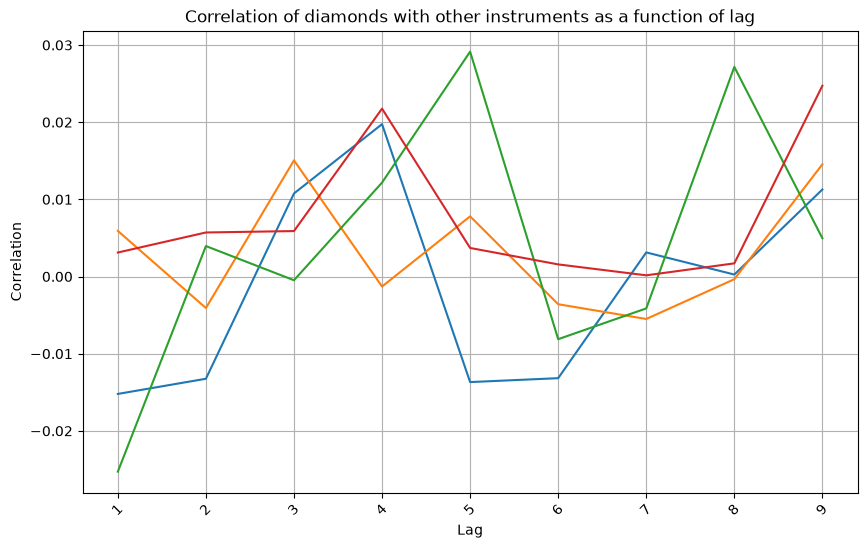

butter
[[-0.01182464  0.00989649  0.0199869   0.01434178]
 [-0.02531692 -0.02035449  0.0093877   0.03146116]
 [ 0.02484078 -0.01931539 -0.00831488 -0.00080642]
 [ 0.01474623 -0.01147008  0.00479729  0.02505227]
 [-0.01039221  0.00715149 -0.00380698 -0.01239687]
 [-0.01580335 -0.00997908 -0.00658468 -0.01291102]
 [ 0.00493977  0.00606476 -0.02056682 -0.01074555]
 [-0.01399503  0.01551     0.00418567 -0.01598179]
 [-0.01577291  0.0067027  -0.01117579  0.00267106]]


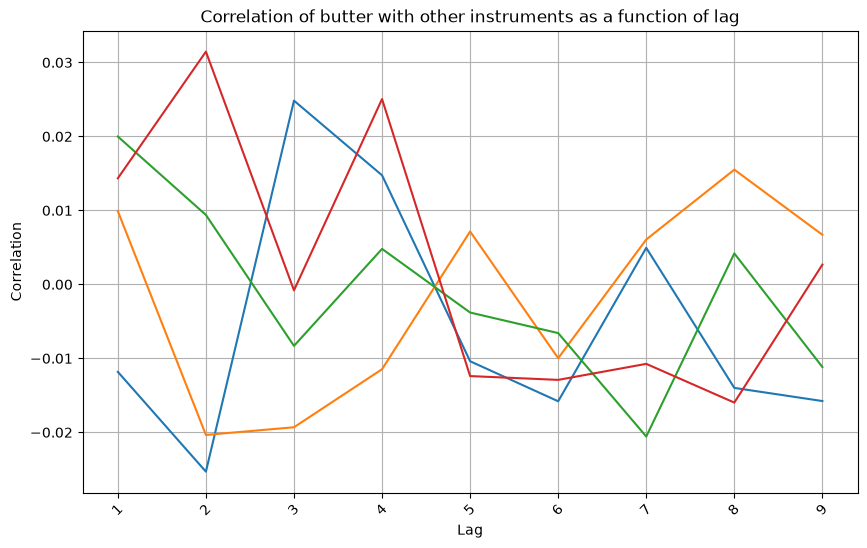

cars
[[-0.00920218 -0.02370353 -0.0124385  -0.0127885 ]
 [-0.00289324  0.00846092 -0.00802466  0.00393512]
 [ 0.01172387 -0.00929251 -0.00433365 -0.00254014]
 [ 0.00642364  0.01460474  0.01892784  0.01145504]
 [-0.01644726 -0.02206366  0.00125944 -0.01130173]
 [-0.02139125 -0.03539723 -0.01995499  0.02214701]
 [-0.01077058  0.00657877 -0.00788508  0.00315826]
 [-0.01797567 -0.00643148  0.01302114 -0.02102914]
 [ 0.00832051  0.00751617  0.02532708 -0.00692802]]


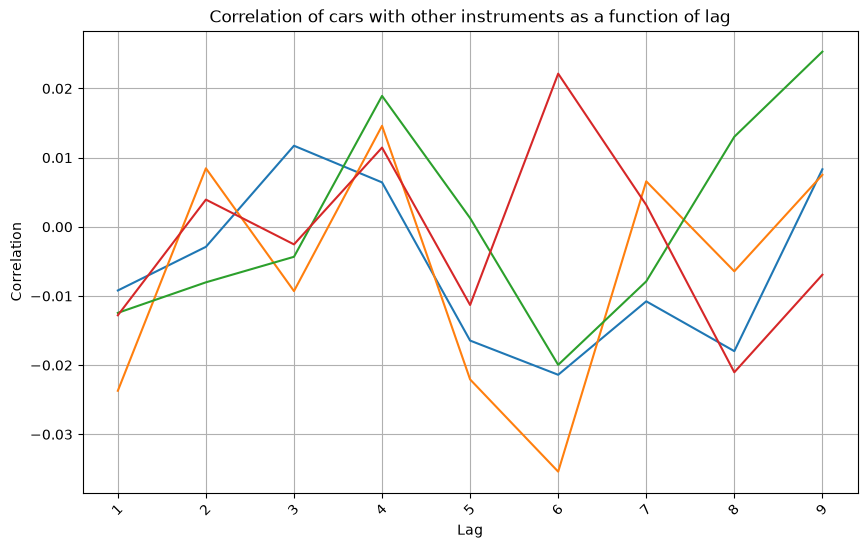

cucumber
[[ 0.00722395 -0.00191719  0.01898621  0.01200519]
 [ 0.00407157 -0.0077536  -0.0002756  -0.0055984 ]
 [-0.00477244 -0.00909407  0.00622233  0.00175573]
 [ 0.00864611 -0.00072151 -0.00768445  0.00502047]
 [-0.00395454  0.00770288  0.02109179 -0.00284322]
 [ 0.0166801  -0.0073105  -0.00754276 -0.00373621]
 [ 0.03381513  0.01384039 -0.0252923  -0.00338697]
 [ 0.00579566  0.01341731  0.02280074 -0.00423354]
 [-0.01684166 -0.0052982  -0.02920571  0.00056101]]


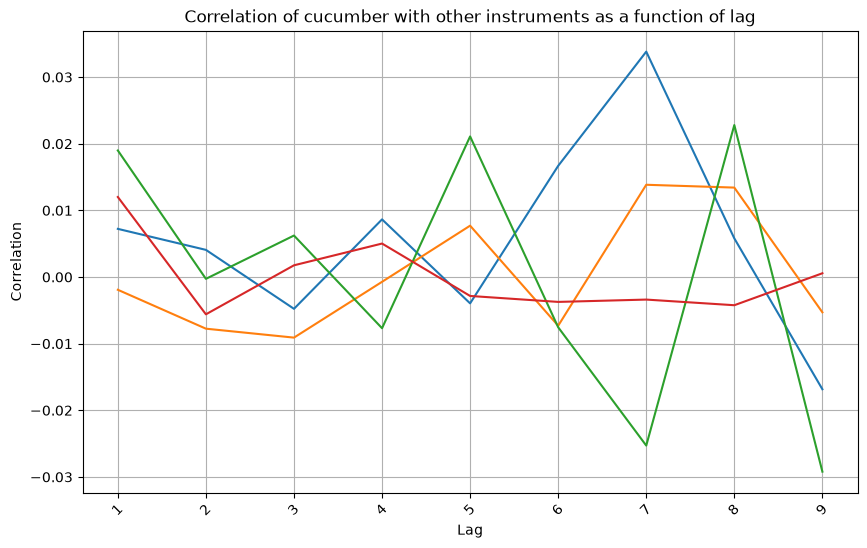

bananas
[[-0.00032211 -0.01589535 -0.02529737 -0.0242091 ]
 [-0.0025781   0.01898329 -0.01850783  0.01968559]
 [ 0.00367624  0.00121254  0.00911897  0.00614597]
 [ 0.01729385  0.02006952 -0.0171758   0.00267373]
 [ 0.01121553 -0.02739707 -0.02807677  0.0097918 ]
 [-0.00705041 -0.03086107  0.01319711  0.00291243]
 [-0.01819398  0.01816543  0.03294648  0.00892711]
 [-0.01080643 -0.00592728 -0.01651999  0.00096796]
 [ 0.0244559  -0.00144594 -0.01216553  0.01219645]]


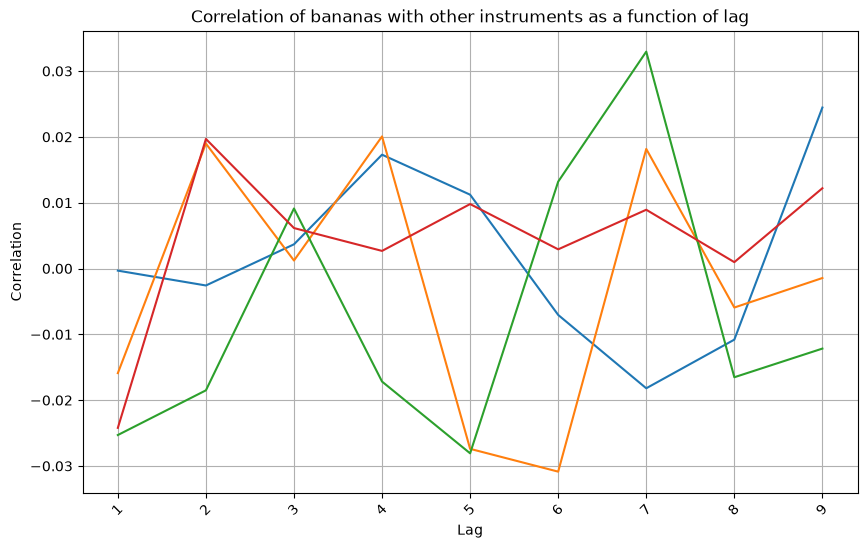

In [22]:
# first look at correlation between return of instruments versus return of other instruments as a function of time lag
for main_instrument in instruments:
    corrs = []
    print(main_instrument)
    for lag in range(1, 10):
        corr = ret.select(pl.col(main_instrument).shift(lag).alias("main"), pl.exclude(DATE, main_instrument))[11:].corr()[0]
        corrs.append(np.array(corr)[0][1:])
    corrs = np.array(corrs)
    print(corrs)
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, 10), corrs)
    plt.xticks(rotation=45)
    plt.title(f"Correlation of {main_instrument} with other instruments as a function of lag")
    plt.xlabel("Lag")
    plt.grid()
    plt.ylabel("Correlation")
    plt.show()


In [23]:
# Now I normalize returns before calculating correlation, to see if that changes the results
vol = ret.select(DATE, pl.col(instruments).pow(2).rolling_mean(100, min_samples=10).sqrt().shift(1))
norm_ret = ret.select(DATE, *[(pl.col(c) / vol[c]).fill_nan(None).alias(c) for c in instruments])

diamonds
[[-0.00508017 -0.00213783 -0.01682074 -0.00490453]
 [-0.01069714 -0.00466247  0.0163854   0.00775843]
 [ 0.02105866  0.01502326  0.00167916  0.00348452]
 [ 0.02706725  0.00656693 -0.00801449  0.02212564]
 [-0.00727666  0.00880179  0.01992975  0.00364501]
 [-0.00322737 -0.00673133 -0.01665746 -0.0042772 ]
 [-0.00144529  0.01530592  0.00235725  0.00205527]
 [-0.00625651  0.00727215  0.02273056  0.00067619]
 [ 0.02026619  0.0115461   0.00079604  0.02517465]]


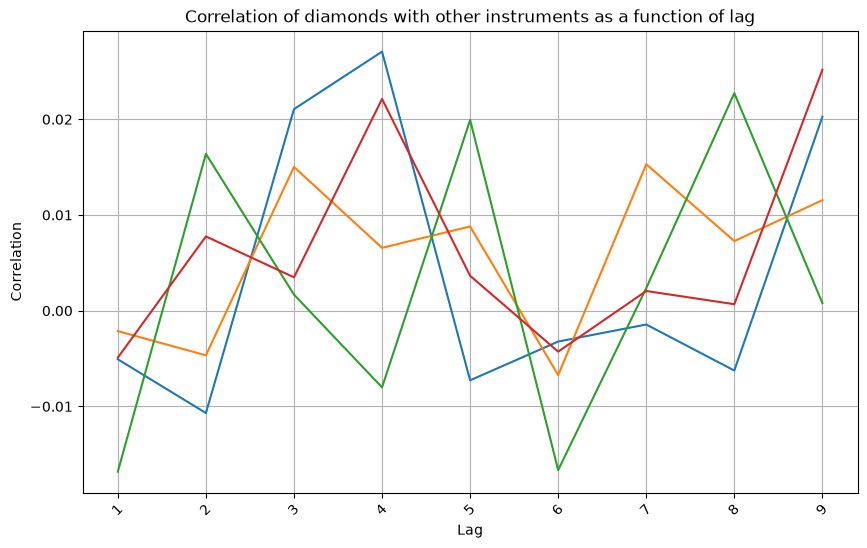

butter
[[-0.01055473  0.00011252  0.01763291  0.01596591]
 [-0.02557521 -0.01588436  0.00998835  0.02576266]
 [ 0.03501108 -0.02248817 -0.00768953 -0.0031754 ]
 [ 0.01286444 -0.01653146  0.00365526  0.01729572]
 [-0.01828867  0.00284386 -0.00014207 -0.01984481]
 [-0.00935004 -0.01186638 -0.00709398 -0.012732  ]
 [-0.00385946  0.00562805 -0.01513539 -0.00464762]
 [-0.01445862  0.01797622  0.00434972 -0.00718443]
 [-0.00211192  0.00638633 -0.00517997  0.00978332]]


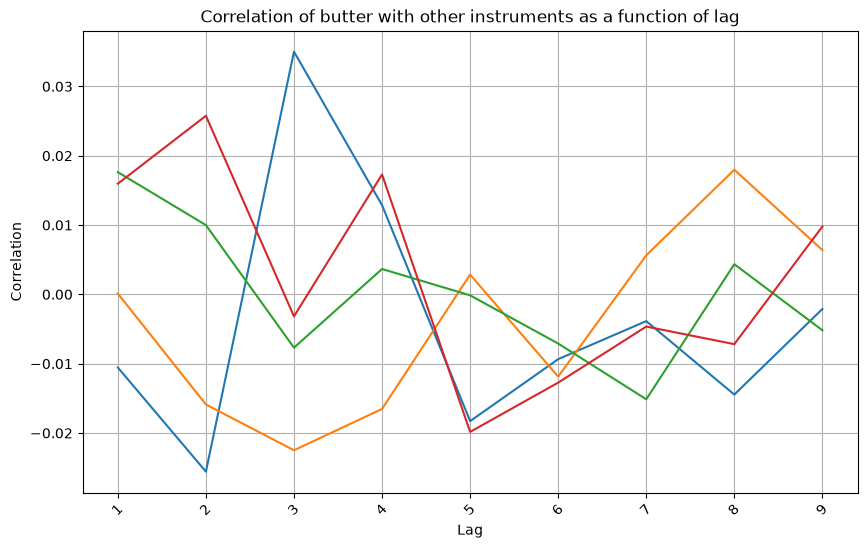

cars
[[-0.00842195 -0.02594348 -0.01166737 -0.00479153]
 [-0.01042315  0.00535428 -0.01300334  0.00229798]
 [ 0.00914106 -0.01289935 -0.00501857 -0.00288149]
 [ 0.00573906  0.01223832  0.0182556   0.01269579]
 [-0.01381083 -0.02883544 -0.00627498 -0.00936094]
 [-0.0130369  -0.03157281 -0.01867096  0.02742535]
 [ 0.00155435  0.01485711 -0.00385362  0.01477809]
 [-0.002935   -0.01274565  0.00509546 -0.01306904]
 [ 0.01297081  0.00926342  0.01950968 -0.00689288]]


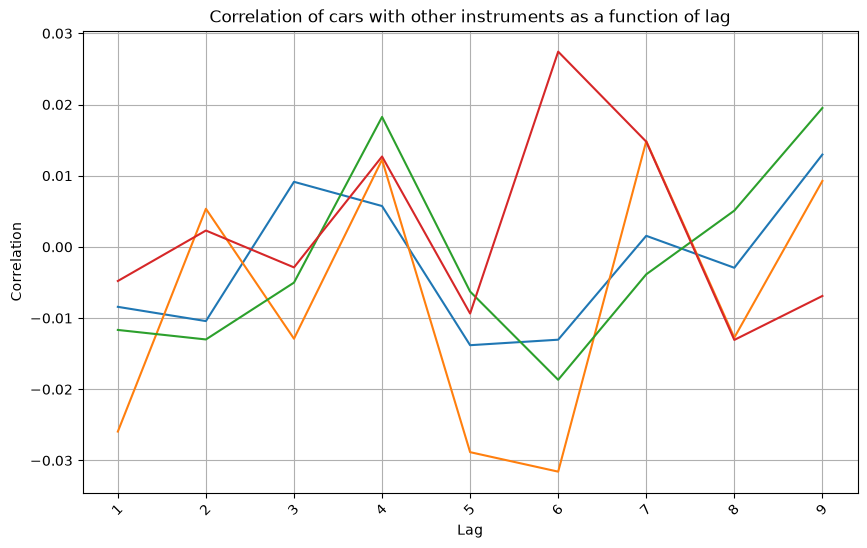

cucumber
[[ 0.00057972 -0.00152003  0.025493    0.01094414]
 [ 0.00934998 -0.00039531 -0.00037622 -0.00197887]
 [-0.00406193 -0.00652244 -0.00033695  0.00424063]
 [ 0.01555568  0.00407954 -0.0066766   0.01054698]
 [-0.00579574  0.00532909  0.01245987  0.00145925]
 [ 0.004187   -0.01248872 -0.01404152 -0.00427199]
 [ 0.03387906  0.01434848 -0.02714685 -0.00474483]
 [ 0.00502107  0.01181302  0.01848793 -0.00266974]
 [ 0.00579866 -0.01017677 -0.03290899 -0.00620521]]


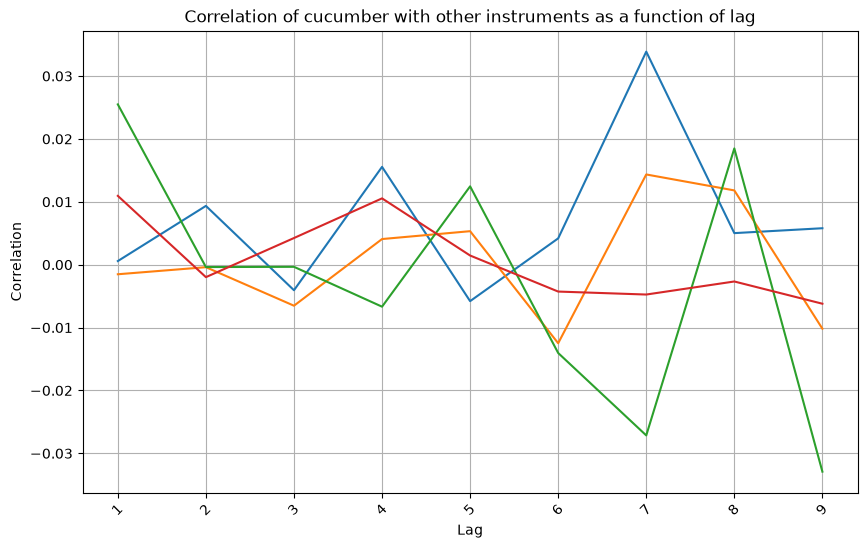

bananas
[[ 0.00220595 -0.0158184  -0.02206361 -0.02301047]
 [-0.00232428  0.01235587 -0.02949936  0.00980141]
 [ 0.00792905 -0.01799947 -0.00030003  0.00117334]
 [ 0.01268302  0.00965186 -0.00698829  0.00637688]
 [ 0.01057539 -0.02759795 -0.01692566  0.00640153]
 [-0.0129831  -0.03431659  0.01253439  0.01080299]
 [-0.01995984  0.01162613  0.0300016   0.01512651]
 [-0.01589306 -0.00405765 -0.01410067  0.00046148]
 [ 0.02698859 -0.01122251 -0.01836557  0.01303985]]


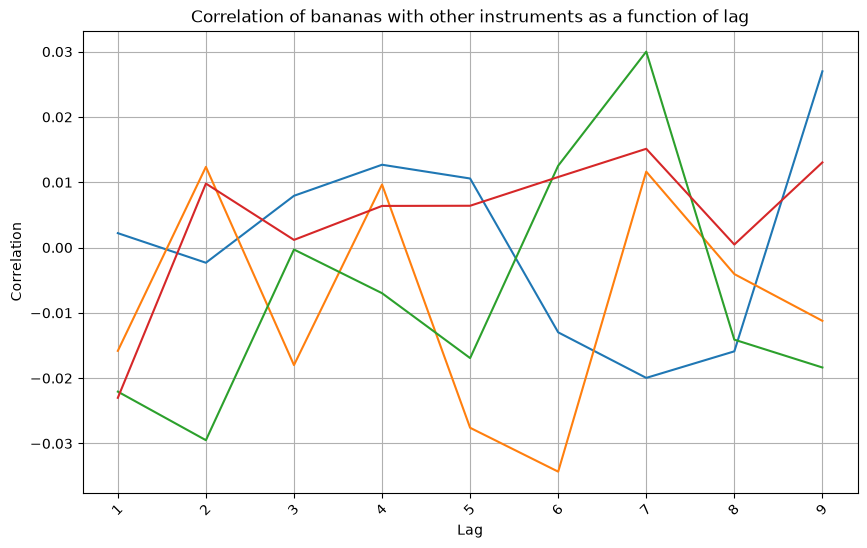

In [25]:
for main_instrument in instruments:
    corrs = []
    print(main_instrument)
    for lag in range(1, 10):
        corr = norm_ret.select(pl.col(main_instrument).shift(lag).alias("main"), pl.exclude(DATE, main_instrument))[100:].corr()[0]
        corrs.append(np.array(corr)[0][1:])
    corrs = np.array(corrs)
    print(corrs)
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, 10), corrs)
    plt.xticks(rotation=45)
    plt.title(f"Correlation of {main_instrument} with other instruments as a function of lag")
    plt.xlabel("Lag")
    plt.grid()
    plt.ylabel("Correlation")
    plt.show()


In [16]:
import numpy as np
import scipy as sp
print(type(np.zeros((3, 3))))

<class 'numpy.ndarray'>


In [149]:
training_data = np.random.rand(4000, 4) # timesteps, features
training_data = np.meshgrid(np.arange(4000),np.ones(4))[0].T
prediction_matrix = np.random.rand(4,10) # features, lags
print(training_data[:,0])

[   0    1    2 ... 3997 3998 3999]


In [180]:

# calculate timestep 12

step12 = np.sum(training_data[12-12:12-2,:].T@prediction_matrix.T,1)
print(step12)


#calculate timesteps 12-4000
steps = np.empty((4000-12,4))
for i in range(4000-12):
    steps[i] = np.sum(training_data[i:i+10,:].T@prediction_matrix.T,1)



[85.53745231 85.53745231 85.53745231 85.53745231]


In [192]:
C = np.roll(sp.linalg.circulant(training_data.T),-1,axis=2)[:,:,-10:][:,:-12,::-1]
steps_fast = np.sum(C@prediction_matrix.T,axis=2)
steps_fast = steps_fast.T


In [201]:

from scipy.optimize import least_squares
func = lambda x: (np.reshape(x,(3,3))@np.array([[1,2,3],[4,5,6],[7,8,9]])- np.array([[1,2,3],[4,5,6],[7,8,9]])).flatten()

result = least_squares(func, np.ones(9))
print(result.x.reshape((3,3)))

[[ 0.83333335  0.3333333  -0.16666665]
 [ 0.33343843  0.33312314  0.33343843]
 [-0.16656151  0.33312302  0.83343849]]


In [61]:

D =np.sum(C@B.T,axis=2).T
print(D.shape)

for i in range(3900):
    E = np.sum(A[i:i+10].T@B.T,axis=1)
    print(E)
    print(D[i])
    print(np.all(E==D[i]))


(4000, 4)
[ 9.1720577   9.89024269 10.06399437  7.76267947]
[ 9.00803461  9.38649069 10.87535089 10.19176976]
False
[9.2868719  9.73997655 9.63852073 7.94548041]
[ 8.02938587 10.58280907  9.84742074  8.42996235]
False
[8.71479386 9.01479417 9.26451292 8.52193498]
[9.27811488 8.54391548 8.11308401 7.40095894]
False
[10.4141523   8.075552    8.30794953  7.03254241]
[8.73719603 7.84671027 9.21564934 7.56990764]
False
[9.43281992 9.64278352 8.37997322 8.54567046]
[9.56835423 8.41616667 8.98392673 7.43549059]
False
[8.00851297 9.17497677 9.45525176 8.11215918]
[9.18065108 9.52215637 6.90637958 6.81194652]
False
[8.18540149 8.28709322 7.76403969 6.01062016]
[8.63659739 7.52780821 7.65736322 7.67447669]
False
[9.0664292  7.13777594 7.00652453 7.37198863]
[10.03754245  6.47452027  8.69821352  7.88713877]
False
[10.08760132  7.4561055  10.35498228  9.26601365]
[10.71103485  9.63214468  8.3146573   8.02414457]
False
[10.64280857  8.84455685  8.827708    8.48319857]
[ 8.99502482 10.24765374 10.66

In [ ]:
A = np.meshgrid(np.arange(4),np.ones(4))[0]
print(A)
B = sp.linalg.circulant(A)
print(B.shape)

print(np.roll(A,1,axis=1) == B[:,:,1])



[[0 1 2 3]
 [0 1 2 3]
 [0 1 2 3]
 [0 1 2 3]]
(4, 4, 4)
[[ True  True  True  True]
 [ True  True  True  True]
 [ True  True  True  True]
 [ True  True  True  True]]


In [206]:
A = np.ones((4,10))

B = np.ones((1,10))

print(A-B)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]
